# 04. Learned signal-reference ratio histograms with 10M selected events per source

Reuse the matching completed 08 event/prediction cache, or generate simulation **in Colab**, applying notebook 02's
frozen preselection until each of S, SBI, B, NI, NI-up and NI-down has at least
10 million selected events. Use exactly 10 million per source for the primary
histograms, with 250k and 1M prefixes as MC convergence controls.
Keep the filtered trained ensembles, no floor, power $a=1$ and 36 primary bins.
Generation, GPU predictions and histogram accumulation resume from Drive.

### Parallel signal-reference study

This notebook parallels **08**. It uses $p(x;\eta)/p_S(x)$ with **$a=1$**
in place of $p(x;\eta)/p(x;1)$ with $a=100$. Both are normalized selected
shapes. The fixed process-ratio axes already use $p_S(x)$ and are unchanged.
The scalar observable remains frozen throughout each physical fit.

Keep the same run name, filtered ensembles, MC campaign, bin edges, physical
model, fit settings and study sequence. No additional reference events are
needed when the matching 10M cache exists. Notebook 04 fills new histograms
from those cached predictions and publishes `colab_04_baseline.json`;
05--07 require that completed manifest. Outputs and checkpoints are separate
from 08--11. Run **04, then 05, 06 and 07**; 07 uses direct templates and does
not require successful interpolation in 05.

Power controls are rescaled to $a=0.5,1,1.5$, retaining the same relative
variations around the new baseline. The event-cache seed and chunk settings
match 08; keep them unchanged to reuse exactly the same events.

### Runtime and persistent run

Use **a Colab GPU runtime** and Run all from the top. Existing models and the
preselection are reused; no training or cluster submission is needed. The new
simulation is independent of the original training and integration samples.
Keep RUN_NAME, Unity model directory and filter policy as in notebook 03.
The Unity directory here is only the existing model bundle already on Drive.

Checkpoints persist on Drive; interrupted chunks are replayed. Restart the
runtime and Run all to resume. GPU model files are staged on Colab local disk;
events and predictions are processed in bounded chunks. The 60M selected events
are never concatenated in RAM. Allow roughly 2.2 GB on Drive for selected
coordinates and three float64 ratios per event, plus small manifests/templates;
local model staging uses additional disk. Rejected events are not saved.

In [1]:
import os
import sys
from pathlib import Path

RUN_NAME = "paper-distinct-s-v4"
MODE = os.environ.get("POODEMO_MODE", "production")  # production or smoke
CONFIG_OVERRIDES = {}  # e.g. {"quadrature_per_process": 500_000, "epochs": 150}
JAX_BACKEND = os.environ.get("POODEMO_JAX_BACKEND", "auto")  # auto, gpu, or cpu

SOURCE_COMMIT = "6ef001cb22c678f8fbf8f82f6290344d82d4b6d7"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    requested_backend = JAX_BACKEND.strip().lower()
    if requested_backend not in ("auto", "gpu", "cpu"):
        raise ValueError("JAX_BACKEND must be auto, gpu, or cpu")
    selected_backend = requested_backend
    if requested_backend == "auto":
        try:
            gpu_probe = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                                       capture_output=True, text=True, timeout=10)
            gpu_present = gpu_probe.returncode == 0 and bool(gpu_probe.stdout.strip())
        except (OSError, subprocess.TimeoutExpired):
            gpu_present = False
        selected_backend = "gpu" if gpu_present else "cpu"
    # CUDA-only selection fails visibly if initialization fails. Keep PyTorch's
    # CUDA visibility and avoid JAX reserving most GPU memory before training.
    jax_platform = "cuda" if selected_backend == "gpu" else "cpu"
    os.environ["JAX_PLATFORMS"] = jax_platform
    os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT = Path(os.environ.get("POODEMO_ROOT", f"/content/drive/MyDrive/poodemo/runs/{RUN_NAME}"))
    import tempfile
    # Download afresh even in a reused runtime; do not alter older checkouts.
    REPO_DIR = Path(tempfile.mkdtemp(prefix="poodemo-04-", dir="/content"))
    print(f"Notebook 04 source: {SOURCE_COMMIT} (fresh download)")
    if not (REPO_DIR / "pyproject.toml").exists():
        import getpass
        import io
        import shutil
        import tarfile
        import urllib.error
        import urllib.request

        archive_url = f"https://api.github.com/repos/rafaellopesdesa/poodemo/tarball/{SOURCE_COMMIT}"

        def fetch_source(token=None):
            headers = {"Accept": "application/vnd.github+json", "User-Agent": "poodemo-colab"}
            if token:
                headers["Authorization"] = "Bearer " + token
            request = urllib.request.Request(archive_url, headers=headers)
            with urllib.request.urlopen(request, timeout=180) as response:
                return response.read()

        try:
            archive_bytes = fetch_source()
        except urllib.error.HTTPError as error:
            if error.code not in (401, 403, 404):
                raise RuntimeError(f"Repository download failed (HTTP {error.code}).") from None
            token = None
            try:
                from google.colab import userdata
                token = userdata.get("GITHUB_TOKEN")
            except Exception:
                pass
            if not token:
                token = getpass.getpass("GitHub token with read access to poodemo: ").strip()
            if not token:
                raise RuntimeError("Provide a GitHub token with read access to download the pinned notebook 04 source.")
            try:
                archive_bytes = fetch_source(token)
            except urllib.error.HTTPError as auth_error:
                raise RuntimeError(f"Repository download failed (HTTP {auth_error.code}); check token access.") from None
            finally:
                token = None

        # Validate archive paths and reject links before extracting the source.
        with tempfile.TemporaryDirectory(prefix="poodemo-source-") as temp:
            staging = Path(temp).resolve()

            def safe_destination(name):
                destination = (staging / name).resolve()
                if not destination.is_relative_to(staging):
                    raise RuntimeError("Unsafe path in source archive.")
                return destination

            with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
                for entry in archive.getmembers():
                    safe_destination(entry.name)
                    if not (entry.isfile() or entry.isdir()):
                        raise RuntimeError("Links and special files are not supported in the source archive.")
                archive.extractall(staging)
            candidates = [p.parent for p in staging.rglob("pyproject.toml") if (p.parent / "poodemo").is_dir()]
            if len(candidates) != 1:
                raise RuntimeError("The downloaded archive must contain one poodemo repository checkout.")
            shutil.copytree(candidates[0], REPO_DIR, dirs_exist_ok=True)
        del archive_bytes

    if os.environ.get("POODEMO_SKIP_INSTALL") != "1":
        from importlib.metadata import version, PackageNotFoundError
        # JAX discovers every installed plugin, even when selecting CPU.
        # Retain already-matched CUDA 12 packages when rerunning GPU setup.
        remove_plugins = []
        for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt", "jax-cuda13-plugin", "jax-cuda13-pjrt"):
            try:
                installed_version = version(package)
            except PackageNotFoundError:
                continue
            if not (selected_backend == "gpu" and package.startswith("jax-cuda12-") and installed_version == "0.5.3"):
                remove_plugins.append(package)
        if remove_plugins:
            subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", *remove_plugins])
        gpu_requirements = (["jax==0.5.3", "jaxlib==0.5.3",
                             "jax-cuda12-plugin[with-cuda]==0.5.3", "jax-cuda12-pjrt==0.5.3"]
                            if selected_backend == "gpu" else [])
        # Resolve with the base requirements so PyTorch's CUDA dependencies are
        # considered together with JAX's. Avoid blanket --upgrade changes.
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r",
                               str(REPO_DIR / "requirements-colab.txt"), *gpu_requirements])
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_DIR)])

        # Check the live notebook kernel before any expensive network training.
        import jax
        import jaxlib
        import jax.numpy as jnp
        if jax.__version__ != "0.5.3" or jaxlib.__version__ != "0.5.3":
            raise RuntimeError("JAX packages are stale in this kernel. Restart the runtime and rerun setup.")
        if selected_backend == "gpu":
            for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt"):
                if version(package) != "0.5.3":
                    raise RuntimeError(f"{package} must match JAX 0.5.3. Restart the runtime and rerun setup.")
        jax.config.update("jax_platforms", jax_platform)
        jax.config.update("jax_enable_x64", True)
        try:
            jax_devices = jax.devices()
            if not jax_devices or any(device.platform != selected_backend for device in jax_devices):
                raise RuntimeError(f"Expected {selected_backend} devices; found {jax_devices}")
            probe_value, probe_gradient = jax.jit(jax.value_and_grad(lambda x: jnp.sum(x*x)))(
                jnp.asarray([1., 2., 3.], dtype=jnp.float64))
            probe_gradient.block_until_ready()
            if (float(probe_value) != 14. or list(probe_gradient) != [2., 4., 6.]
                    or probe_gradient.dtype != jnp.float64
                    or any(device.platform != selected_backend for device in probe_gradient.devices())):
                raise RuntimeError("JAX double-precision value/gradient check failed")
        except Exception as error:
            raise RuntimeError(
                f"JAX {selected_backend} startup failed. Select a Colab GPU runtime if requesting GPU, "
                "then restart the runtime and rerun setup. Use JAX_BACKEND='cpu' only for an intentional CPU run."
            ) from error
        print(f"JAX {jax.__version__} / jaxlib {jaxlib.__version__}: backend={selected_backend}, {jax_devices}; float64 JIT/gradient OK")

    # A new editable install is not activated in an already-running kernel.
    # Expose the inner package directly, including after a failed import cached
    # the outer /content/poodemo checkout as a namespace package.
    import importlib
    source_root = str(REPO_DIR.resolve())
    if source_root in sys.path:
        sys.path.remove(source_root)
    sys.path.insert(0, source_root)
    importlib.invalidate_caches()
    # Run from the top: subsequent cells recreate objects from this checkout.
    # Clear all poodemo submodules, including old plotting and fit functions.
    for module_name in list(sys.modules):
        if module_name == "poodemo" or module_name.startswith("poodemo."):
            del sys.modules[module_name]

else:
    # Locally: pip install -r requirements-colab.txt && pip install -e .
    ROOT = Path(os.environ.get("POODEMO_ROOT", str(Path.home() / "poodemo-runs" / RUN_NAME)))
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "poodemo" / "pipeline.py").exists():
            sys.path.insert(0, str(candidate))
            break

ROOT.mkdir(parents=True, exist_ok=True)
print(f"Run directory: {ROOT}")
print(f"Mode: {MODE}")

Mounted at /content/drive
Notebook 04 source: 6ef001cb22c678f8fbf8f82f6290344d82d4b6d7 (fresh download)


/tmp/ipykernel_895/1897613919.py:99: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(staging)


JAX 0.5.3 / jaxlib 0.5.3: backend=gpu, [CudaDevice(id=0)]; float64 JIT/gradient OK
Run directory: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4
Mode: production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from poodemo.pipeline import create_run

run = create_run(ROOT, mode=MODE, overrides=CONFIG_OVERRIDES)
# Observable-only settings: keep these identical in notebooks 04 and 05.
# The floor changes the observable, never the physical mu or its fit bounds.
N_BINS = 36
REFERENCE_RATIO_ETA_MIN = 0.0  # No floor.
REFERENCE_RATIO_A = 1.0
if not np.isfinite(REFERENCE_RATIO_A) or REFERENCE_RATIO_A <= 0:
    raise ValueError("REFERENCE_RATIO_A must be finite and positive")
if not np.isfinite(REFERENCE_RATIO_ETA_MIN) or not 0 <= REFERENCE_RATIO_ETA_MIN < 1:
    raise ValueError("REFERENCE_RATIO_ETA_MIN must lie in [0, 1)")
run = run.with_config(reference_ratio_denominator="S",
    reference_ratio_power=float(REFERENCE_RATIO_A),
    reference_ratio_eta_floor=float(REFERENCE_RATIO_ETA_MIN),
)
print(f"Reference ratio: {N_BINS} bins, eta floor={REFERENCE_RATIO_ETA_MIN:g}, "
      f"a={REFERENCE_RATIO_A:g}; 0.5 is inside a bin")
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.2})
display(pd.Series(run.config, name="configuration"))

# Bounded zeroing of TOTAL MC bin predictions, in expected event counts.
# Fixed before fitting; larger per-bin OR aggregate deficits remain invalid.
MC_ZERO_MAX_BIN = 0.01
MC_ZERO_MAX_TOTAL = 0.05
run = run.with_config(mc_zero_max_bin=MC_ZERO_MAX_BIN, mc_zero_max_total=MC_ZERO_MAX_TOTAL)
from poodemo.mc_yields import yield_policy
print("MC total-yield policy:", yield_policy(run.config).metadata())

Reference ratio: 36 bins, eta floor=0, a=1; 0.5 is inside a bin


,configuration
schema_version,7
mode,production
seed,20261006
physics_overrides,{}
toolkit_commit,fc09848fc6540fd32310faebbe9db6eea7ecd17b
n_per_sample,5000000
ni_sample_multiplier,10
generation_chunk,250000
preselection_train_cap,1000000
ratio_train_cap,2000000


MC total-yield policy: {'mc_yield_policy': 'bounded_zero_v1', 'mc_zero_max_bin': 0.01, 'mc_zero_max_total': 0.05}


### Tiny negative MC yields

After combining the signed components and applying the NI morph, replace a
negative **total bin mean** by zero only when every correction is at most
$0.01$ expected events and their sum at that parameter point is at most $0.05$.
Both limits are fixed before fitting and shared by 04 and 05. Larger deficits
remain invalid. Positive means, component templates and interference are unchanged;
the corrected total is used consistently in the Poisson rate and logarithm.

Save raw minima, affected bins and summed corrections. A zero prediction with a
positive observed count still has zero Poisson probability. Clipping creates
kinks: Fisher points with negative raw means or zero means with nonzero derivatives
remain invalid. This policy does not freeze $\eta$; the signal reference has no forced collapse at 1.

### Reuse notebook 03's filtered density ratios

Run notebook 03 with the transferred Unity models first. Keep the same
`RUN_NAME`, `MODE`, `CONFIG_OVERRIDES`, `UNITY_MODEL_DIR`, and
`ENSEMBLE_FILTER_POLICY` here. The default directory is
`My Drive/poodemo/unity_models/paper-distinct-s-v4-unity100/`; it contains
`bundle.json`, `campaign.json`, and `ratios/` directly inside it.

The next cell verifies the transferred bundle and reuses notebook 03's frozen
retained-member lists for all five ensembles, including the pointwise outlier
rules. It verifies input, policy and artifact hashes without re-screening or
evaluating analytical densities. Changed inputs require a completed matching
filter run in notebook 03 first; no networks are trained here. `RATIO_SOURCE = "drive"` explicitly
selects the original Drive models instead, with the same filtering rules.

The next cells create an independent Colab simulation cache. The selected
filtered models remain unchanged; predictions on the new events are cached.
All new results use a separate study directory printed below.

In [3]:
import os
from pathlib import Path
from poodemo.data import save_json
from poodemo.ensemble_bundle import use_bundle, BundleEvaluationRun
from poodemo.member_filter import MemberFilterPolicy, unfiltered_run
from poodemo.practical import (PracticalRun, use_practical_run,
                               reuse_filtered_ensembles as filter_ratio_ensembles)

RATIO_SOURCE = "unity"  # "drive" explicitly selects the original saved models.
UNITY_MODEL_DIR = Path(os.environ.get(
    "POODEMO_UNITY_MODEL_DIR",
    "/content/drive/MyDrive/poodemo/unity_models/paper-distinct-s-v4-unity100",
))
ENSEMBLE_FILTER_POLICY = MemberFilterPolicy(
    catastrophic_peer_factor=100.0,
)  # Match notebook 03, including any custom policy settings.

# Unwrap a previous selection so rerunning this cell never nests evaluations.
source_run = run.base_run if isinstance(run, PracticalRun) else run
source_run = unfiltered_run(source_run)
source_run = source_run.base_run if isinstance(source_run, BundleEvaluationRun) else source_run
if RATIO_SOURCE == "unity":
    if not (UNITY_MODEL_DIR / "bundle.json").is_file():
        raise FileNotFoundError(
            f"Copy the complete Unity model bundle to {UNITY_MODEL_DIR}. "
            "Expected bundle.json, campaign.json and ratios/ directly inside it. "
            "Use the same directory as notebook 03; see unity/README.md.")
    ensemble_run = use_bundle(source_run, UNITY_MODEL_DIR)
elif RATIO_SOURCE == "drive":
    ensemble_run = source_run
else:
    raise ValueError("RATIO_SOURCE must be 'drive' or 'unity'")
run = filter_ratio_ensembles(ensemble_run, policy=ENSEMBLE_FILTER_POLICY)
filter_summary = pd.read_csv(run.path("results", "ensemble_filter", "summary.csv"))
display(filter_summary)
print("Ratio source:", RATIO_SOURCE)
print("Retained ratio models:", run.path("models", "ratios"))
print("Evaluation outputs:", run.evaluation_root)
save_json(run.path("results", "reference_ratio_model_source.json"), {
    "ratio_source": RATIO_SOURCE,
    "bundle_directory": str(ensemble_run.bundle) if RATIO_SOURCE == "unity" else None,
    "campaign_id": ensemble_run.bundle_manifest["campaign_id"] if RATIO_SOURCE == "unity" else None,
    "filter_identity": run.filter_manifest["identity"],
    "filter_policy": run.filter_manifest["inputs"]["policy"],
    "evaluation_root": str(run.evaluation_root),
})
_filtered_run = run
run = use_practical_run(run)
print("Practical evaluation:", run.evaluation_root)
# Preserve selected model provenance in the practical evaluation.
save_json(run.path("results","reference_ratio_model_source.json"),
          __import__("json").loads(_filtered_run.path("results","reference_ratio_model_source.json").read_text()))

Reusing frozen notebook-03 member selection: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39


,task,original_members,retained_members,rejected_members,status,log_integral,max_point_mass,effective_fraction,log_normalization
0,SBI_over_S,100,100,0,passed,-0.000666,0.000005,0.989804,0.001621
1,B_over_S,100,100,0,passed,-0.000690,0.000005,0.987958,0.001652
2,NI_over_S,100,100,0,passed,-0.005577,0.000014,0.374248,0.007946
3,NI_up_over_NI,100,96,4,passed,0.000110,0.000012,0.412796,0.000183
4,NI_down_over_NI,100,96,4,passed,-0.000133,0.000015,0.340834,-0.000030


Ratio source: unity
Retained ratio models: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/models/ratios
Evaluation outputs: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39
Practical evaluation: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1


### What changes with the larger sample

Fresh events determine the component **shapes**. The selected process yields
$\nu_j$ remain the estimates from the original integration samples, and the
learned-map normalizers remain fixed on the original held-out S sample.
Each prefix of $N$ fresh selected events receives weight $w_j=\nu_j/N$.
Increasing MC statistics does not change the experimental luminosity or yields.
Acceptance-rate uncertainty is not reduced by this shape-only convergence study.
The selected-target stopping count is never used as an acceptance estimate.

All coordinates use learned ratios. The only analytical inference calculation
is the unbinned benchmark; analytical PDFs are not histogram weights.
Same-template Asimov observations test each fixed MC model, not independent
closure against the true experiment. Prefixes are nested and correlated.
NI retains the existing after-binning morph, including its explicit sparse-bin
convention. Tiny negative total yields use the bounded zeroing policy below. Larger
deficits and nonregular Fisher points remain invalid; bins are not merged.

### Generate and evaluate fresh selected events

The target is **per source after preselection**, not a cap on existing samples.
Progress and hashes are saved after each completed chunk and each ratio task.
A new seed creates a separate independent campaign. Changing batch/chunk settings
creates a separate cache; keep them unchanged when resuming.

In [4]:
from poodemo.colab_mc import (prepare_colab_samples, fill_colab_histograms,
                               template_diagnostics, convergence_scans)
from poodemo.pipeline import _positive_study_grid
import torch

SELECTED_EVENTS_PER_SOURCE = 10_000_000  # AFTER the frozen notebook-02 preselection.
MC_PREFIXES = [250_000, 1_000_000, SELECTED_EVENTS_PER_SOURCE]
MC_SEED = 20261111
SELECTED_CHUNK = 250_000
GENERATION_CHUNK = 250_000
INFERENCE_BATCH = 8192  # Reduce if the GPU runs out of memory.
NORMALIZATION_EVENTS = 250_000  # Original held-out S sample; fixed across MC prefixes.
BIN_COUNTS = [4, 12, 24, 36, 60]
ETA_VALUES = [0.0, 0.3, 0.6, 1.0, 1.5]
COMPARISON_ETA_MIN = 0.2
CHECK_ETAS = [0., 0.99, 0.999, 1., 1.001, 1.01]

if IN_COLAB and not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab, then rerun from the top.")
print("Inference device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU smoke check")
print(f"Target: {SELECTED_EVENTS_PER_SOURCE:,} selected events for EACH of S, SBI, B, NI, NI-up, NI-down")
print("Generation and neural evaluation run here in Colab; no cluster jobs or retraining.")

# Preserve the original practical run for calibration and sample caching.
assert 2 <= SELECTED_EVENTS_PER_SOURCE <= 10_000_000
mc_run = run
samples = prepare_colab_samples(
    mc_run, selected_per_source=SELECTED_EVENTS_PER_SOURCE, seed=MC_SEED,
    selected_chunk=SELECTED_CHUNK, generation_chunk=GENERATION_CHUNK,
    inference_batch=INFERENCE_BATCH, normalization_events=NORMALIZATION_EVENTS,
    model_cache=Path('/content/poodemo-model-cache') if IN_COLAB else None,
)
display(samples['sample_counts'])
print('Persistent sample cache:', samples['directory'])

Inference device: NVIDIA L4
Target: 10,000,000 selected events for EACH of S, SBI, B, NI, NI-up, NI-down
Generation and neural evaluation run here in Colab; no cluster jobs or retraining.
Colab sample cache: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4


,sample,selected_cached,selected_used,generated,frozen_selected_yield,event_weight
0,S,10000000,10000000,10941526,4571.280000,0.000457
1,SBI,10000000,10000000,12463216,38183.511561,0.003818
2,B,10000000,10000000,12483991,40041.000000,0.004004
3,NI,10000000,10000000,110073765,45449.933333,0.004545
4,NI_up,10000000,10000000,79297623,63081.600000,0.006308
5,NI_down,10000000,10000000,157887643,31626.333333,0.003163


Persistent sample cache: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4


In [5]:
# NN predictions are cached. Changing eta/bin settings only refills histograms.
scan_grid = _positive_study_grid(mc_run)
requested_etas = np.unique(np.r_[scan_grid, ETA_VALUES, CHECK_ETAS, 1.,
                                 COMPARISON_ETA_MIN, REFERENCE_RATIO_ETA_MIN,
                                 np.maximum(scan_grid, REFERENCE_RATIO_ETA_MIN)])
requested_bins = sorted(set(BIN_COUNTS + [N_BINS]))
templates = fill_colab_histograms(
    mc_run, samples, etas=requested_etas, bin_counts=requested_bins,
    prefixes=MC_PREFIXES,
)
# Separate results protect historical 04/05 runs and different MC studies.
run = templates.study_run(mc_run)
print('10M-study outputs:', run.evaluation_root)
print('Stored direct templates:', templates.directory / 'counts.npz')

Histogram cache: S 250,000/10,000,000
Histogram cache: S 500,000/10,000,000
Histogram cache: S 750,000/10,000,000
Histogram cache: S 1,000,000/10,000,000
Histogram cache: S 1,250,000/10,000,000
Histogram cache: S 1,500,000/10,000,000
Histogram cache: S 1,750,000/10,000,000
Histogram cache: S 2,000,000/10,000,000
Histogram cache: S 2,250,000/10,000,000
Histogram cache: S 2,500,000/10,000,000
Histogram cache: S 2,750,000/10,000,000
Histogram cache: S 3,000,000/10,000,000
Histogram cache: S 3,250,000/10,000,000
Histogram cache: S 3,500,000/10,000,000
Histogram cache: S 3,750,000/10,000,000
Histogram cache: S 4,000,000/10,000,000
Histogram cache: S 4,250,000/10,000,000
Histogram cache: S 4,500,000/10,000,000
Histogram cache: S 4,750,000/10,000,000
Histogram cache: S 5,000,000/10,000,000
Histogram cache: S 5,250,000/10,000,000
Histogram cache: S 5,500,000/10,000,000
Histogram cache: S 5,750,000/10,000,000
Histogram cache: S 6,000,000/10,000,000
Histogram cache: S 6,250,000/10,000,000
Histog

### Physical-domain and MC precision checks

For each bin, minimize the physical prediction exactly as a quadratic in
$\sqrt{\mu}$ over the configured fit bounds, at a declared grid of NI values.
The nuisance grid is a diagnostic, not a guarantee between its points. Save MC
uncertainties and zero-yield/nonzero-derivative checks at the generating truth.
These run before likelihood fits. Increasing the MC target does not guarantee
that every rare bin becomes valid.

In [6]:
diagnostics = template_diagnostics(run, templates, etas=scan_grid, n_bins=N_BINS)
by_partition = diagnostics.groupby(['selected_per_source','eta']).agg(
    minimum_expected=('minimum_expected','min'), negative_bins=('negative','sum'),
    nonregular_bins_at_truth=('nonregular_mu_at_truth','sum'),
    zeroed_bins_at_test=('zeroed_at_test','sum'),
    zeroed_total_at_test=('test_zeroed_total','max'),
    test_zeroing_accepted=('test_zeroing_accepted','all'),
).reset_index()
display(by_partition.groupby('selected_per_source').agg(
    partitions=('eta','size'), raw_domain_minimum=('minimum_expected','min'),
    partitions_with_raw_negatives=('negative_bins',lambda x:int((x>0).sum())),
    corrected_test_points=('zeroed_bins_at_test',lambda x:int((x>0).sum())),
    max_test_correction=('zeroed_total_at_test','max'),
    rejected_test_points=('test_zeroing_accepted',lambda x:int((~x).sum())),
    nonregular_partitions_at_truth=('nonregular_bins_at_truth',lambda x:int((x>0).sum())),
))
print('Raw domain minima are retained; bounded zeroing is audited separately at each tested point.')
display(diagnostics.loc[diagnostics.negative | diagnostics.nonregular_mu_at_truth].head(30))
print('Full raw/used bin diagnostics:',run.path('results','reference_ratio_mc_bin_diagnostics.csv'))

,partitions,raw_domain_minimum,partitions_with_raw_negatives,corrected_test_points,max_test_correction,rejected_test_points,nonregular_partitions_at_truth
selected_per_source,,,,,,,
250000,83,0.000000,0,0,0.000000,0,0
1000000,83,0.000000,0,0,0.000000,0,0
10000000,83,-0.001659,39,24,0.000734,0,39


Raw domain minima are retained; bounded zeroing is audited separately at each tested point.


,selected_per_source,eta,bin,minimum_expected,mu_at_minimum,alpha_at_minimum,negative,truth_mean,nonregular_mu_at_truth,expected_at_test,mc_sigma_at_test,expected_used_at_test,zeroed_at_test,test_zeroing_accepted,test_negative_total,test_zeroed_total,incomplete_NI_support_bins
7592,10000000,0.769630,32,-0.001659,2.0,-3.0,True,0.0,True,0.000491,0.000491,0.000491,False,True,0.000000,0.000000,0
7628,10000000,0.786667,32,-0.001659,2.0,-3.0,True,0.0,True,0.000453,0.000453,0.000453,False,True,0.000000,0.000000,0
7664,10000000,0.803704,32,-0.001659,2.0,-3.0,True,0.0,True,0.000414,0.000414,0.000414,False,True,0.000000,0.000000,0
7700,10000000,0.820741,32,-0.001659,2.0,-3.0,True,0.0,True,0.000377,0.000377,0.000377,False,True,0.000000,0.000000,0
7736,10000000,0.837778,32,-0.001659,2.0,-3.0,True,0.0,True,0.000339,0.000339,0.000339,False,True,0.000000,0.000000,0
7772,10000000,0.854815,32,-0.001659,2.0,-3.0,True,0.0,True,0.000302,0.000302,0.000302,False,True,0.000000,0.000000,0
7808,10000000,0.871852,32,-0.001659,2.0,-3.0,True,0.0,True,0.000265,0.000265,0.000265,False,True,0.000000,0.000000,0
7844,10000000,0.888889,32,-0.001659,2.0,-3.0,True,0.0,True,0.000229,0.000229,0.000229,False,True,0.000000,0.000000,0
7880,10000000,0.905926,32,-0.001659,2.0,-3.0,True,0.0,True,0.000193,0.000193,0.000193,False,True,0.000000,0.000000,0
7916,10000000,0.922963,32,-0.001659,2.0,-3.0,True,0.0,True,0.000157,0.000157,0.000157,False,True,0.000000,0.000000,0


Full raw/used bin diagnostics: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/3d3b831e79db5a49d9d5/inference_581b0fd4c797/results/reference_ratio_mc_bin_diagnostics.csv


### Ratio to the selected signal density

At nominal NI nuisance, define the learned, selected and normalized ratio
$$
R^S_\eta(x)=\frac{p(x;\eta_{\mathrm{eff}},0)}{p_S(x)},\qquad
\eta_{\mathrm{eff}}=\max(\eta,\eta_{\min}),\qquad
z^S_\eta(x)=\operatorname{sigmoid}\!\left(a\log R^S_\eta(x)\right).
$$
The baseline is **no floor**, **$a=1$**, and **36 bins**, so
$z^S_\eta=R^S_\eta/(1+R^S_\eta)$. The denominator is the selected pure-signal
shape, not the physical mixture at $\mu=1$. It stays fixed during every fit.

Use the same filtered learned component ratios $\hat r_j$, frozen normalizers
$Z_j=\langle\hat r_j\rangle_{S,\mathrm{MC}}$, and selected rates $\nu_j$:
$$
\hat f_\eta(x)=\sum_j c_j(\eta)\nu_j\hat r_j(x)/Z_j,\qquad
\nu_\eta=\sum_j c_j(\eta)\nu_j,\qquad
R^S_\eta=\frac{\hat f_\eta/\nu_\eta}{\hat f_S/\nu_S}.
$$
Here $\hat r_S=Z_S=1$, hence $\hat f_S/\nu_S=1$; the unknown common
$p_S(x)$ cancels. No analytical density is evaluated to define the observable.
Selected rates and normalizers never depend on data, toys or fitted parameters.
The extended Poisson term retains the event-rate information.

There is **no forced collapse at $\eta=1$**: the physical mixture generally
has a different shape from pure signal. Changing the reference can change
which information the scalar compression retains, but does not guarantee
sufficiency for a global fit over all physical $\mu$ or for NI profiling.
The sigmoid is invertible before binning; finite bins can lose information.

Retain the exact same half-step bin edges as 08--11, including 0.5 inside a
bin, for a controlled parallel. Physical coefficients, nuisance morphing,
fit bounds, MC prefixes and bounded total-yield zeroing are unchanged.
The explicit 0.2-floor control remains a separate study, not the baseline.

### How the observable changes with eta

Each curve uses the observable constructed at $\eta$ itself in the no-floor
baseline. Edit `ETA_VALUES` and `N_BINS` below. $\eta=0$ is supported for these
distribution plots; likelihood and information scans use positive test points.
At $\eta=1$ the observable remains the physical mixture divided by pure signal.

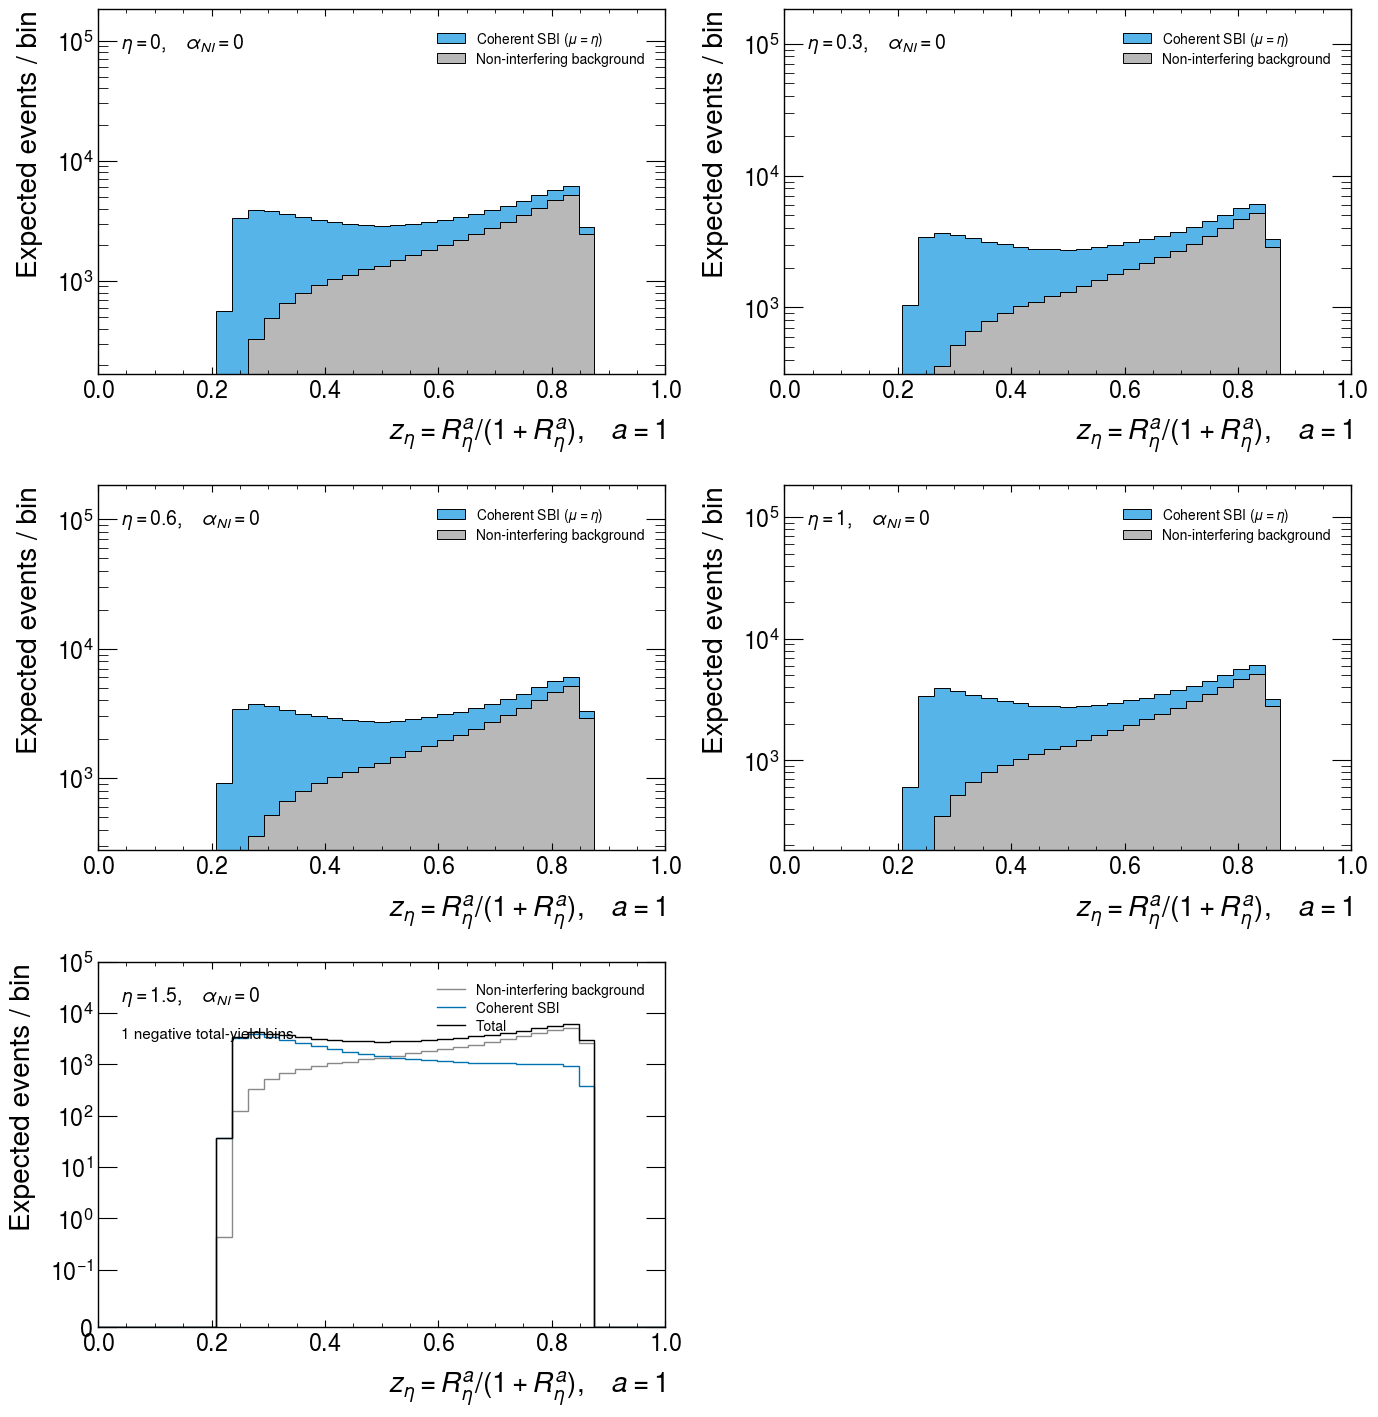

,eta,coherent_SBI_yield,NI_yield,total_yield,minimum_bin_yield
0,0.0,40041.000000,45449.933333,85490.933333,0.0000
1,0.3,37891.202509,45449.933333,83341.135842,0.0000
2,0.6,37804.065380,45449.933333,83253.998713,0.0000
3,1.0,38183.511561,45449.933333,83633.444894,0.0000
4,1.5,39024.318825,45449.933333,84474.252158,-0.0009


In [7]:
import mplhep as hep
from poodemo.pipeline import observable_bin_edges
OBSERVABLE = 'reference_ratio'
PLOT_PREFIX = '04'
OBSERVABLE_LABEL = rf"$z_\eta=R_\eta^a/(1+R_\eta^a),\quad a={REFERENCE_RATIO_A:g}$"
HIST_BINS = N_BINS
edges = observable_bin_edges(HIST_BINS, OBSERVABLE)
distributions = []
for eta in ETA_VALUES:
    nu_s, nu_sbi, nu_b, nu_ni = templates.anchors(max(eta, REFERENCE_RATIO_ETA_MIN), HIST_BINS)[0]
    root_eta = np.sqrt(eta)
    coherent = (eta-root_eta)*nu_s + root_eta*nu_sbi + (1-root_eta)*nu_b
    distributions.append((eta, coherent, nu_ni))

# Each panel has its own scale. Signed components remain visible on symlog.
with plt.style.context(hep.style.ATLAS), plt.rc_context({'font.size': 14}):
    ncols = min(2, len(distributions)); nrows = (len(distributions)+ncols-1)//ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 4.8*nrows), squeeze=False)
    for ax, (eta, coherent, ni) in zip(axes.flat, distributions):
        total = coherent+ni
        if np.any(coherent < 0):
            hep.histplot([ni, coherent, total], bins=edges, histtype='step',
                         color=['#888888','#0072B2','black'],
                         label=['Non-interfering background', 'Coherent SBI', 'Total'], yerr=False, ax=ax)
            ax.set_yscale('symlog', linthresh=.1)
            ax.text(.04,.79,f'{np.count_nonzero(total < 0)} negative total-yield bins', transform=ax.transAxes, fontsize=11)
        else:
            hep.histplot([ni,coherent], bins=edges, stack=True, histtype='fill',
                         color=['#B8B8B8','#56B4E9'], edgecolor='black', linewidth=.7,
                         label=['Non-interfering background', r'Coherent SBI ($\mu=\eta$)'], yerr=False, ax=ax)
            ax.set_yscale('log')
            positive=total[total>0]
            if len(positive): ax.set_ylim(max(.001,positive.min()*.3),positive.max()*30)
        ax.text(.04,.94,fr'$\eta={eta:g},\quad\alpha_{{NI}}=0$',transform=ax.transAxes,va='top')
        ax.set(xlim=(0,1),xlabel=OBSERVABLE_LABEL,ylabel='Expected events / bin')
        ax.legend(fontsize=10,loc='upper right'); ax.grid(False)
    for ax in axes.flat[len(distributions):]: ax.set_visible(False)
    fig.tight_layout()
    for ext in ('png','pdf'): fig.savefig(run.path('plots', f'04_reference_ratio_distributions.{ext}'),dpi=160,bbox_inches='tight')
    plt.show()
display(pd.DataFrame([dict(eta=e, coherent_SBI_yield=c.sum(), NI_yield=n.sum(),
                           total_yield=(c+n).sum(),minimum_bin_yield=(c+n).min()) for e,c,n in distributions]))

In [8]:
ranges = templates.collapse_table(CHECK_ETAS, N_BINS)
display(ranges)
# eta=1 is a regular signal-reference observable; do not force one occupied bin.
np.testing.assert_allclose(templates.anchors(1.,N_BINS)[0].sum(axis=-1), samples['rates'][:4], rtol=1e-12)
ranges.to_csv(run.path('results','signal_ratio_ranges.csv'),index=False)

,eta,n_bins,z_min,z_max,occupied_bins,central_low,central_high
0,0.000,36,0.227461,0.867132,24,0.486111,0.513889
1,0.990,36,0.228878,0.879003,25,0.486111,0.513889
2,0.999,36,0.228987,0.879139,25,0.486111,0.513889
3,1.000,36,0.228999,0.879154,25,0.486111,0.513889
4,1.001,36,0.229011,0.879169,25,0.486111,0.513889
5,1.010,36,0.229120,0.879303,25,0.486111,0.513889


### Freeze the observable inside each fit

At each test set $\eta=\mu_0$, then freeze learned event coordinates, edges and
MC Asimov observations throughout the null and free fits. Only the physical
coefficients and NI nuisance change. The no-floor setting does not restrict
the physical fit domain. Learned ratios carry no exact sufficiency guarantee.

### Refresh the analytical unbinned benchmark

This is the only oracle inference calculation. It provides a reference for the
learned-coordinate MC histograms. Notebook 03 retains its separate learned-model
closure comparisons. The new benchmark is saved in the practical evaluation.

In [9]:
from poodemo.practical import refresh_analytic_reference
unbinned = refresh_analytic_reference(run)
display(unbinned)
print("Analytical unbinned benchmark refreshed; all histogram inputs remain simulation-based.")

,mu,model,systematics,q,valid,mu_hat,alpha_NI,fit_message,truth_certified,asimov_mu
0,0.020000,analytic unbinned,False,15.864207,True,1.0,0.000000,NI fixed at zero; unrestricted truth attains n...,True,1.0
1,0.037037,analytic unbinned,False,10.013895,True,1.0,0.000000,NI fixed at zero; unrestricted truth attains n...,True,1.0
2,0.054074,analytic unbinned,False,7.088403,True,1.0,0.000000,NI fixed at zero; unrestricted truth attains n...,True,1.0
3,0.071111,analytic unbinned,False,5.524872,True,1.0,0.000000,NI fixed at zero; unrestricted truth attains n...,True,1.0
4,0.088148,analytic unbinned,False,4.715026,True,1.0,0.000000,NI fixed at zero; unrestricted truth attains n...,True,1.0
...,...,...,...,...,...,...,...,...,...,...
161,1.331852,analytic unbinned,True,6.169591,True,1.0,-0.018434,Resolved basins and endpoints searched; unrest...,True,1.0
162,1.348889,analytic unbinned,True,6.877127,True,1.0,-0.019522,Resolved basins and endpoints searched; unrest...,True,1.0
163,1.365926,analytic unbinned,True,7.628080,True,1.0,-0.020622,Resolved basins and endpoints searched; unrest...,True,1.0
164,1.382963,analytic unbinned,True,8.423096,True,1.0,-0.021734,Resolved basins and endpoints searched; unrest...,True,1.0


Analytical unbinned benchmark refreshed; all histogram inputs remain simulation-based.


### MC convergence at fixed map and yields

scan_points  valid_points
selected_per_source systematics                           
250000              False                 83            83
                    True                  83            83
1000000             False                 83            83
                    True                  83            83
10000000            False                 83            83
                    True                  83            83

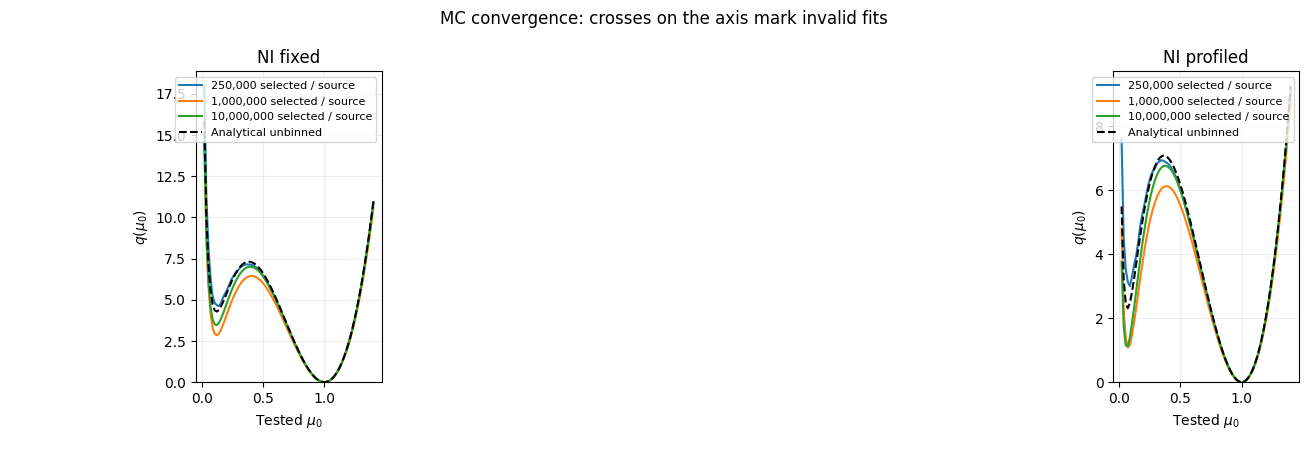

In [10]:
mc_scans = convergence_scans(run, templates, etas=scan_grid, n_bins=N_BINS)
display(mc_scans.groupby(['selected_per_source','systematics']).agg(
    scan_points=('valid','size'), valid_points=('valid','sum')))
fig, axes = plt.subplots(1,2,figsize=(13,4.5),sharex=True)
for ax, syst in zip(axes,[False,True]):
    for size, group in mc_scans.loc[mc_scans.systematics.eq(syst)].groupby('selected_per_source'):
        group=group.sort_values('mu')
        line,=ax.plot(group.mu,group.q.where(group.valid),label=f'{size:,} selected / source')
        bad=group.loc[~group.valid]
        ax.plot(bad.mu,np.zeros(len(bad)),marker='x',ls='none',color=line.get_color(),
                transform=ax.get_xaxis_transform(),clip_on=False)
    ref=unbinned.loc[unbinned.systematics.eq(syst)].sort_values('mu')
    ax.plot(ref.mu,ref.q.where(ref.valid),'k--',label='Analytical unbinned')
    ax.set(xlabel=r'Tested $\mu_0$',ylabel=r'$q(\mu_0)$',title='NI profiled' if syst else 'NI fixed',ylim=(0,None))
    ax.legend(fontsize=8)
fig.suptitle('MC convergence: crosses on the axis mark invalid fits')
fig.tight_layout();fig.savefig(run.path('plots','04_mc_convergence.png'),dpi=160,bbox_inches='tight');plt.show()

In [11]:
from poodemo.pipeline import run_binning_study
binning_run = run.with_config(bin_counts=BIN_COUNTS)
binning = run_binning_study(binning_run, observable="reference_ratio", template_bank=templates)
display(binning["scans"])
display(binning["fidelity"])
display(binning['scans'].groupby(['model','n_bins'],dropna=False).agg(
    scan_points=('valid','size'), valid_points=('valid','sum')))

Matched reference_ratio eta=0.02: fits checked (inspect valid flags)
Matched reference_ratio eta=0.037: fits checked (inspect valid flags)
Matched reference_ratio eta=0.0541: fits checked (inspect valid flags)
Matched reference_ratio eta=0.0711: fits checked (inspect valid flags)
Matched reference_ratio eta=0.0881: fits checked (inspect valid flags)
Matched reference_ratio eta=0.105: fits checked (inspect valid flags)
Matched reference_ratio eta=0.122: fits checked (inspect valid flags)
Matched reference_ratio eta=0.139: fits checked (inspect valid flags)
Matched reference_ratio eta=0.156: fits checked (inspect valid flags)
Matched reference_ratio eta=0.173: fits checked (inspect valid flags)
Matched reference_ratio eta=0.19: fits checked (inspect valid flags)
Matched reference_ratio eta=0.207: fits checked (inspect valid flags)
Matched reference_ratio eta=0.224: fits checked (inspect valid flags)
Matched reference_ratio eta=0.241: fits checked (inspect valid flags)
Matched reference_r

,mu,model,systematics,q,valid,raw_minimum,negative_bins,largest_negative,negative_total,zeroing_accepted,...,observable_source,template_source,simulation_per_sample,reference_ratio_denominator,reference_ratio_power,reference_ratio_eta_floor,reference_ratio_eta_policy,eta_effective,eta_reference,reference_denominator
0,0.020000,direct reference_ratio histogram,False,13.907164,True,0.0,0.0,0.0,0.0,True,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
1,0.020000,direct reference_ratio histogram,False,14.452365,True,0.0,0.0,0.0,0.0,True,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
2,0.020000,direct reference_ratio histogram,False,14.619131,True,0.0,0.0,0.0,0.0,True,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
3,0.020000,direct reference_ratio histogram,False,14.648406,True,0.0,0.0,0.0,0.0,True,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
4,0.020000,direct reference_ratio histogram,False,14.705825,True,0.0,0.0,0.0,0.0,True,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576,1.331852,analytic unbinned,False,7.291489,True,NaN,NaN,NaN,NaN,NaN,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,NaN,NaN,S
577,1.348889,analytic unbinned,False,8.135337,True,NaN,NaN,NaN,NaN,NaN,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,NaN,NaN,S
578,1.365926,analytic unbinned,False,9.031990,True,NaN,NaN,NaN,NaN,NaN,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,NaN,NaN,S
579,1.382963,analytic unbinned,False,9.982307,True,NaN,NaN,NaN,NaN,NaN,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,NaN,NaN,S


,eta,n_bins,information_valid,information_fraction,shape_information_fraction,full_information,binned_information,occupied_bins,observable,binning_policy,...,observable_source,template_source,simulation_per_sample,reference_ratio_denominator,reference_ratio_power,reference_ratio_eta_floor,reference_ratio_eta_policy,eta_effective,eta_reference,reference_denominator
0,0.02,4,True,0.968658,0.899773,5660.242101,5482.838335,3,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
1,0.02,12,True,0.995690,0.986218,5660.242101,5635.848054,8,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
2,0.02,24,True,0.999173,0.997355,5660.242101,5655.559946,17,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
3,0.02,36,True,0.999991,0.999970,5660.242101,5660.189642,24,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
4,0.02,60,True,1.000521,1.001665,5660.242101,5663.189048,40,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,1.40,4,True,0.929065,0.862938,84.237851,78.262453,3,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S
411,1.40,12,False,NaN,NaN,84.237851,NaN,9,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S
412,1.40,24,True,0.993007,0.986488,84.237851,83.648780,16,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S
413,1.40,36,False,NaN,NaN,84.237851,NaN,25,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S


scan_points  valid_points
model                            n_bins                           
analytic unbinned                NaN              83            83
direct reference_ratio histogram 4.0              83            83
                                 12.0             83            83
                                 24.0             83            83
                                 36.0             83            83
                                 60.0             83            83
fixed reference_ratio histogram  60.0             83            83

In [12]:
def plot_scans(frame, title, filename, group_columns=None, *, xlim=None, ylim=None):
    """Plot saved scans with optional (min, max) axis limits.

    Omit xlim/ylim to retain the default view. A None endpoint keeps that
    bound unchanged, for example ylim=(0, None) or xlim=(None, 1.2).
    """
    x_column = next((c for c in ["mu", "mu_test", "mu0"] if c in frame.columns), None)
    y_column = next((c for c in ["q", "t_mu", "test_statistic", "ts"] if c in frame.columns), None)
    if x_column is None or y_column is None:
        raise ValueError(f"Expected mu and q scan columns; found {list(frame.columns)}")
    if group_columns is None:
        group_columns = [c for c in ["method", "model", "systematics", "nuisances", "n_bins", "bins", "observable"] if c in frame.columns]
    groups = frame.groupby(group_columns, dropna=False, sort=False) if group_columns else [("scan", frame)]
    fig, ax = plt.subplots()
    for label, group in groups:
        group = group.sort_values(x_column)
        values = label if isinstance(label, tuple) else (label,)
        parts = []
        for column, value in zip(group_columns, values):
            if pd.isna(value):
                continue
            if column == "systematics":
                parts.append("profiled" if value else "stat only")
            elif column in ("n_bins", "bins"):
                parts.append(f"{int(value)} bins")
            else:
                parts.append(str(value))
        ax.plot(group[x_column], group[y_column].where(group["valid"]) if "valid" in group else group[y_column], marker=".", ms=3, label=" | ".join(parts))
        # Invalid fits are shown on the x axis, never joined by a valid curve.
        if "valid" in group:
            bad = group.loc[~group["valid"]]
            ax.plot(bad[x_column], np.zeros(len(bad)), "rx", transform=ax.get_xaxis_transform(), clip_on=False)
    ax.axhline(1.0, color="0.45", ls=":", lw=1)
    ax.set(xlabel=r"Tested signal strength $\mu_0$", ylabel=r"$t(\mu_0)$", title=title)
    ax.set_ylim(bottom=0)
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.legend(fontsize=8)
    fig.tight_layout()
    output = run.path("plots")
    output.mkdir(exist_ok=True)
    fig.savefig(output / filename, bbox_inches="tight")
    plt.show()
    return fig

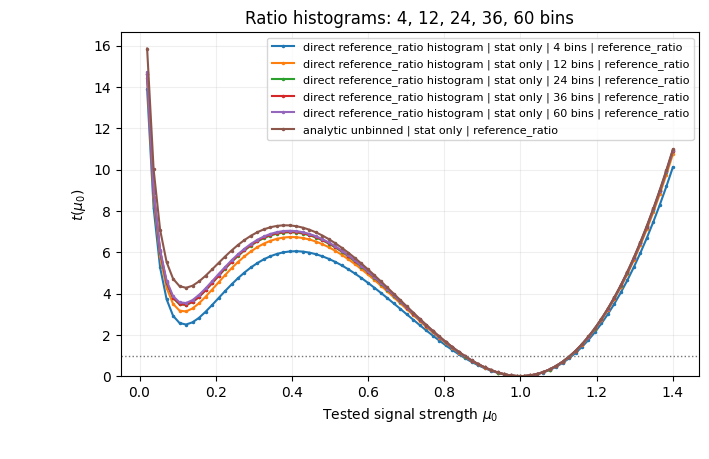

In [13]:
SCAN_BIN_COUNTS = [4, 12, 24, 36, 60]
scans = binning["scans"]
shown_scans = scans.loc[
    (scans["model"].eq("direct reference_ratio histogram") & scans["n_bins"].isin(SCAN_BIN_COUNTS))
    | scans["model"].eq("analytic unbinned")
    | scans["model"].str.startswith("learned unbinned", na=False)
].copy()
SCAN_XLIM = None  # Set None to show the full scan range.
SCAN_YLIM = None  # Set None to show the full vertical range.
scan_title = "Ratio histograms: " + ", ".join(map(str, SCAN_BIN_COUNTS)) + " bins"
plot_scans(shown_scans, scan_title, "04_binning_scans.pdf",
           xlim=SCAN_XLIM, ylim=SCAN_YLIM);

### Finite-separation tests and local information

Learned ratios need not be sufficient. Compare the binned likelihood with the
analytical unbinned benchmark. Local information at $\mu=\eta$ differs from the
later width study at fixed truth $\mu_*=1$. MC template noise can put information
ratios above one; that is a convergence diagnostic, not a physical gain over the
full likelihood. There is no imposed loss of all shape information at $\eta=1$.

,eta,n_bins,information_valid,information_fraction,shape_information_fraction,full_information,binned_information,occupied_bins,observable,binning_policy,...,observable_source,template_source,simulation_per_sample,reference_ratio_denominator,reference_ratio_power,reference_ratio_eta_floor,reference_ratio_eta_policy,eta_effective,eta_reference,reference_denominator
0,0.02,4,True,0.968658,0.899773,5660.242101,5482.838335,3,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
1,0.02,12,True,0.995690,0.986218,5660.242101,5635.848054,8,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
2,0.02,24,True,0.999173,0.997355,5660.242101,5655.559946,17,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
3,0.02,36,True,0.999991,0.999970,5660.242101,5660.189642,24,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
4,0.02,60,True,1.000521,1.001665,5660.242101,5663.189048,40,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,0.02,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,1.40,4,True,0.929065,0.862938,84.237851,78.262453,3,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S
411,1.40,12,False,NaN,NaN,84.237851,NaN,9,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S
412,1.40,24,True,0.993007,0.986488,84.237851,83.648780,16,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S
413,1.40,36,False,NaN,NaN,84.237851,NaN,25,reference_ratio,reference_halfstep_interior_v1,...,filtered_learned,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.40,NaN,S


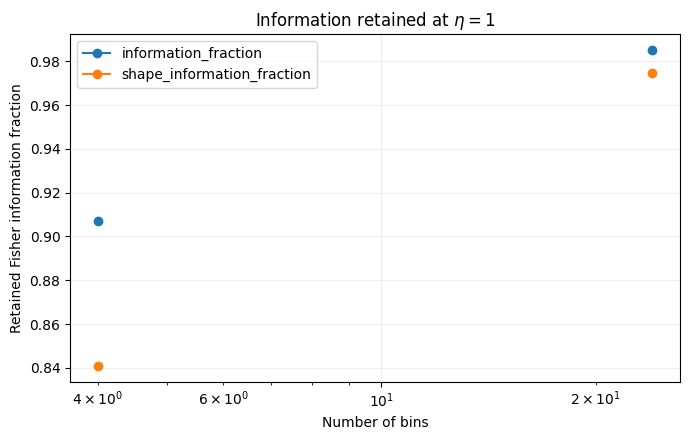

In [14]:
PLOT_PREFIX = '04'

fidelity = binning["fidelity"]
display(fidelity)
eta_near_truth = min(fidelity["eta"].unique(), key=lambda e: abs(e - run.config["asimov_mu"]))
at_anchor = fidelity[np.isclose(fidelity["eta"], eta_near_truth)].sort_values("n_bins")
y_columns = [c for c in fidelity if "information_fraction" in c]
if y_columns:
    ax = at_anchor.plot(x="n_bins", y=y_columns, marker="o", logx=True)
    ax.set(xlabel="Number of bins", ylabel="Retained Fisher information fraction",
           title=fr"Information retained at $\eta={eta_near_truth:.3g}$")
    ax.figure.tight_layout()
    (run.path("plots")).mkdir(exist_ok=True)
    ax.figure.savefig(run.path("plots") / f"{PLOT_PREFIX}_binning_diagnostics.pdf", bbox_inches="tight")
    plt.show()

### Estimator and local uncertainty versus the frozen observable

Now hold the generating experiment fixed at $(\mu_*,\alpha_{NI})=(\mu_*,0)$
and vary only the observable anchor $\eta$. Each row refills the
**same Asimov expectation**, freezes that histogram, and fits physical
$\mu$, with NI either fixed or profiled. For an identified, correctly
modeled Asimov experiment, $\hat\mu(\eta)$ should remain at the
generating value. This is not a study of finite-sample fluctuations.

The width is evaluated from the local Fisher information at the fixed
truth, using the extended likelihood and the NI auxiliary constraint:
$$
\sigma_\mu^{\rm fixed}(\eta)=1/\sqrt{I_{\mu\mu}^{(\eta)}},\qquad
\sigma_\mu^{\rm profiled}(\eta)
=\sqrt{[(\mathbf I^{(\eta)})^{-1}]_{\mu\mu}}.
$$
This is the local Asimov curvature of **each frozen-observable fit**.
It is neither the curvature of the scan that changes $\eta=\mu_0$
at every point nor a global confidence interval. A second likelihood
minimum can produce additional accepted parameter regions that a local
width cannot describe.

The full unbinned reference does not depend on $\eta$. For the binned
comparison, profiled widths use nuisance morphing after binning, as in
the spline notebook; its difference from integrating the unbinned morphing is a
separate model effect. Inspect anomalous fitted values for optimizer
failure or multiple equally good minima before interpreting them as
compression bias.

Use the primary 36-bin estimator resolution, explicitly passed as `N_BINS`.
The independent `BIN_COUNTS` sweep does not change this estimator setting.
The truth stays fixed while $\eta$ changes. The baseline uses no floor. The signal reference has no forced rate-only point. Multiple physical $\mu$ values
can nevertheless compete in a coarse or information-losing compression. A different fitted branch need not indicate optimizer
failure. Local widths do not describe global ambiguity; invalid widths are
reported rather than floored.

The next cells compare **no floor** with an explicit **$0.2$ floor control**,
using the same 36 bins, fresh MC bank, Asimov truth, $\eta$ grid, nuisance treatments
and physical fit bounds. Primary estimator outputs retain the baseline settings;
the positive-floor control writes separate `reference_ratio_estimator_eta_floor_control`
files. A low-$\eta$ zoom highlights the affected region; the vertical line marks
the comparison floor.
These are **local widths at the fixed Asimov truth**, not confidence-interval
coverage or a proof of improved global likelihood fits. The free-fit MLE panels
remain a separate diagnostic. Values at $\eta\geq0.2$ should agree between
the two binned prescriptions because their partitions are then identical.

In [15]:
from poodemo.diagnostics import run_estimator_study

print("Estimator-study bin count:", N_BINS)
# Primary study uses the configured baseline (no floor by default).
estimator_study = run_estimator_study(run, observable="reference_ratio", n_bins=N_BINS, template_bank=templates)
# Explicit floor control; it must remain distinct when the baseline is zero.
no_floor_run = run.with_config(reference_ratio_eta_floor=0.0)
estimator_no_floor = (estimator_study if REFERENCE_RATIO_ETA_MIN == 0.0 else
    run_estimator_study(no_floor_run, observable="reference_ratio", n_bins=N_BINS, template_bank=templates,
                        output_tag="reference_ratio_estimator_eta_no_floor"))
floor_run = run.with_config(reference_ratio_eta_floor=COMPARISON_ETA_MIN)
estimator_floor = (estimator_study if REFERENCE_RATIO_ETA_MIN == COMPARISON_ETA_MIN else
    run_estimator_study(floor_run, observable="reference_ratio", n_bins=N_BINS, template_bank=templates,
                        output_tag="reference_ratio_estimator_eta_floor_control"))
np.testing.assert_array_equal(np.sort(estimator_floor["eta"].unique()),
                              np.sort(estimator_no_floor["eta"].unique()))
FLOOR_LABEL = f"{N_BINS} bins, floor={COMPARISON_ETA_MIN:g}"
NO_FLOOR_LABEL = f"{N_BINS} bins, no floor"
# Include a single analytical baseline per eta and NI treatment.
is_unbinned = estimator_study["model"].eq("analytic unbinned")
estimator_comparison = pd.concat([
    estimator_floor.loc[~estimator_floor["model"].eq("analytic unbinned")]
        .assign(observable_variant=FLOOR_LABEL),
    estimator_no_floor.loc[~estimator_no_floor["model"].eq("analytic unbinned")]
        .assign(observable_variant=NO_FLOOR_LABEL),
    estimator_study.loc[is_unbinned].assign(observable_variant="Analytical unbinned"),
], ignore_index=True)
display(estimator_comparison)
invalid_rows = estimator_comparison[
    ~estimator_comparison["fit_valid"] | ~estimator_comparison["width_valid"]]
if len(invalid_rows):
    print("Invalid fits or local widths (omitted from the corresponding curves):")
    display(invalid_rows)
estimator_comparison.to_csv(
    run.path("results", "reference_ratio_estimator_eta_floor_comparison.csv"), index=False)
print("Primary baseline estimator table:", run.path("results", "reference_ratio_estimator_eta.csv"))
print("Floor control (when different from baseline):", run.path("results", "reference_ratio_estimator_eta_floor_control.csv"))

Estimator-study bin count: 36
Estimator and local-width study at eta=0.02 ready
Estimator and local-width study at eta=0.037 ready
Estimator and local-width study at eta=0.0541 ready
Estimator and local-width study at eta=0.0711 ready
Estimator and local-width study at eta=0.0881 ready
Estimator and local-width study at eta=0.105 ready
Estimator and local-width study at eta=0.122 ready
Estimator and local-width study at eta=0.139 ready
Estimator and local-width study at eta=0.156 ready
Estimator and local-width study at eta=0.173 ready
Estimator and local-width study at eta=0.19 ready
Estimator and local-width study at eta=0.207 ready
Estimator and local-width study at eta=0.224 ready
Estimator and local-width study at eta=0.241 ready
Estimator and local-width study at eta=0.259 ready
Estimator and local-width study at eta=0.276 ready
Estimator and local-width study at eta=0.293 ready
Estimator and local-width study at eta=0.31 ready
Estimator and local-width study at eta=0.327 ready
E

,eta,model,n_bins,morph_order,incomplete_NI_support_bins,truth,information_mu,mu_hat,mu_hat_minus_truth,alpha_NI_hat,...,template_source,simulation_per_sample,reference_ratio_denominator,reference_ratio_power,reference_ratio_eta_floor,reference_ratio_eta_policy,eta_effective,eta_reference,reference_denominator,observable_variant
0,0.020000,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.200000,NaN,S,"36 bins, floor=0.2"
1,0.020000,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,1.102131e-08,-5.502340e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.200000,NaN,S,"36 bins, floor=0.2"
2,0.037037,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.200000,NaN,S,"36 bins, floor=0.2"
3,0.037037,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,1.102131e-08,-5.502340e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.200000,NaN,S,"36 bins, floor=0.2"
4,0.054074,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.200000,NaN,S,"36 bins, floor=0.2"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,1.365926,analytic unbinned,0,unbinned,NaN,1.0,1.0,1.0,2.041168e-08,-3.545141e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.365926,NaN,S,Analytical unbinned
494,1.382963,analytic unbinned,0,unbinned,NaN,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.382963,NaN,S,Analytical unbinned
495,1.382963,analytic unbinned,0,unbinned,NaN,1.0,1.0,1.0,2.041168e-08,-3.545141e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.382963,NaN,S,Analytical unbinned
496,1.400000,analytic unbinned,0,unbinned,NaN,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.400000,NaN,S,Analytical unbinned


Invalid fits or local widths (omitted from the corresponding curves):


,eta,model,n_bins,morph_order,incomplete_NI_support_bins,truth,information_mu,mu_hat,mu_hat_minus_truth,alpha_NI_hat,...,template_source,simulation_per_sample,reference_ratio_denominator,reference_ratio_power,reference_ratio_eta_floor,reference_ratio_eta_policy,eta_effective,eta_reference,reference_denominator,observable_variant
88,0.769630,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.769630,NaN,S,"36 bins, floor=0.2"
89,0.769630,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,1.102190e-08,-5.512266e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.769630,NaN,S,"36 bins, floor=0.2"
90,0.786667,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.786667,NaN,S,"36 bins, floor=0.2"
91,0.786667,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,1.109591e-08,-5.513266e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.786667,NaN,S,"36 bins, floor=0.2"
92,0.803704,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.2,lower_floor_v1,0.803704,NaN,S,"36 bins, floor=0.2"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,1.365926,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,1.108461e-08,-5.512362e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.365926,NaN,S,"36 bins, no floor"
328,1.382963,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.382963,NaN,S,"36 bins, no floor"
329,1.382963,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,1.099992e-08,-5.505993e-09,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.382963,NaN,S,"36 bins, no floor"
330,1.400000,direct reference_ratio histogram,36,after,0.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,...,generated_colab_mc_v1,10000000,S,1.0,0.0,lower_floor_v1,1.400000,NaN,S,"36 bins, no floor"


Primary baseline estimator table: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/3d3b831e79db5a49d9d5/inference_581b0fd4c797/results/reference_ratio_estimator_eta.csv
Floor control (when different from baseline): /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/3d3b831e79db5a49d9d5/inference_581b0fd4c797/results/reference_ratio_estimator_eta_floor_control.csv


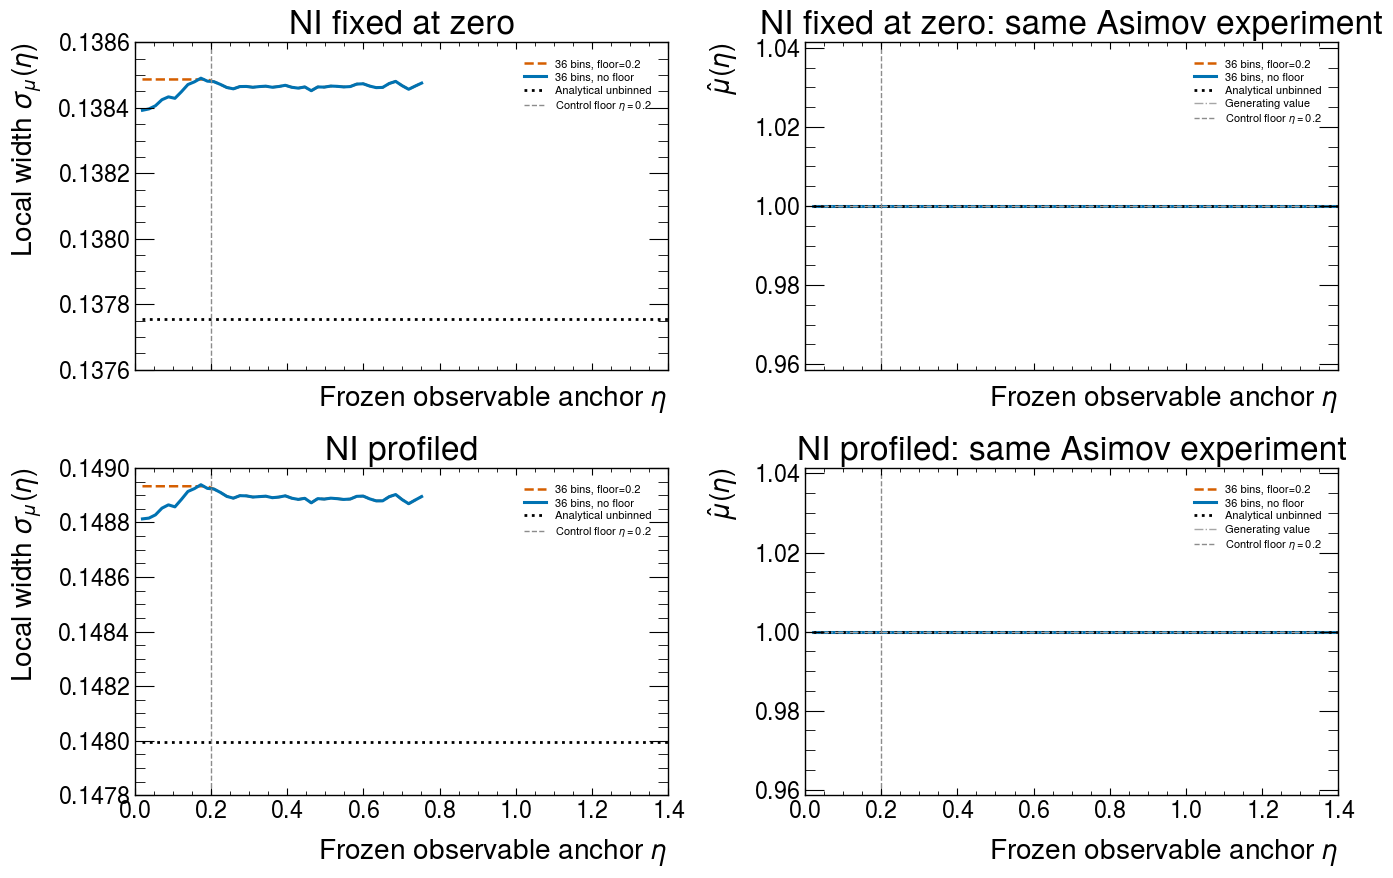

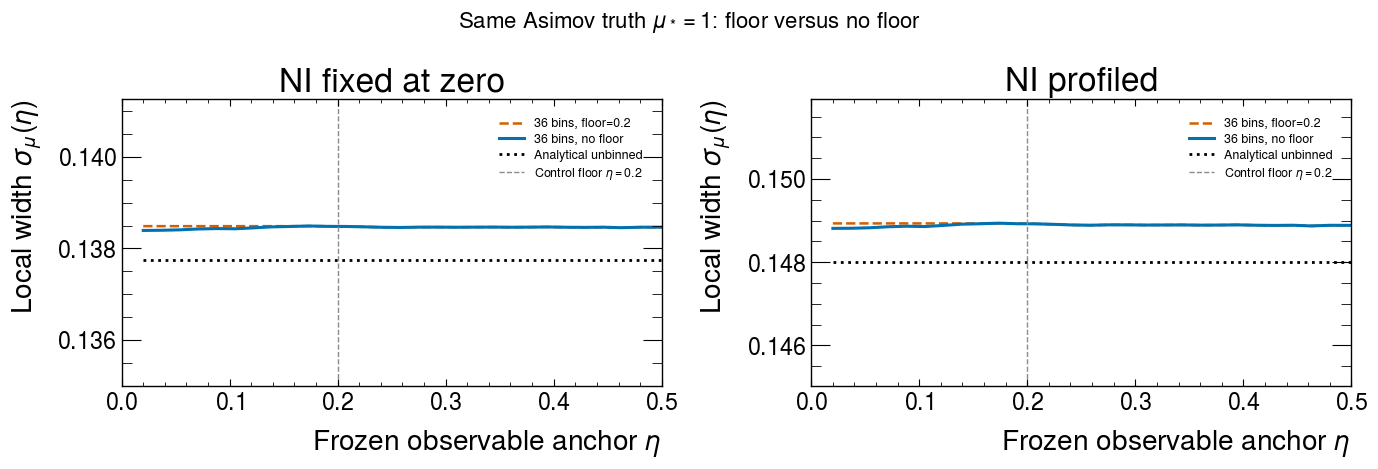

In [16]:
PLOT_PREFIX = '04'
ESTIMATOR_ZOOM_XLIM = (0.0, 0.5)  # Low-eta width comparison; edit to change the zoom.

import mplhep as hep

truth_mu = float(estimator_study["truth"].iloc[0])
estimator_styles = {
    FLOOR_LABEL: dict(color="#D55E00", linestyle="--", linewidth=1.8),
    NO_FLOOR_LABEL: dict(color="#0072B2", linestyle="-", linewidth=2.2),
    "Analytical unbinned": dict(color="black", linestyle=":", linewidth=2.0),
}

def estimator_curves(systematic):
    subset = estimator_comparison.loc[estimator_comparison["systematics"].eq(systematic)]
    for label, style in estimator_styles.items():
        values = subset.loc[subset["observable_variant"].eq(label)].sort_values("eta")
        yield label, values, style

def mark_estimator_floor(ax):
    if COMPARISON_ETA_MIN > 0:
        ax.axvline(COMPARISON_ETA_MIN, color="0.55", ls="--", lw=1,
                   label=fr"Control floor $\eta={COMPARISON_ETA_MIN:g}$")
    ax.grid(False)

with plt.style.context(hep.style.ATLAS), plt.rc_context({"font.size": 14}):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, squeeze=False)
    for row, systematic in enumerate([False, True]):
        for label, values, style in estimator_curves(systematic):
            sigma = values["sigma_mu"].replace([np.inf, -np.inf], np.nan).where(values["width_valid"])
            axes[row, 0].plot(values["eta"], sigma, label=label, **style)
            axes[row, 1].plot(values["eta"], values["mu_hat"].where(values["fit_valid"]),
                              label=label, **style)
        nuisance_label = "NI profiled" if systematic else "NI fixed at zero"
        axes[row, 0].set(title=nuisance_label, ylabel=r"Local width $\sigma_\mu(\eta)$")
        axes[row, 1].axhline(truth_mu, color="0.65", ls="-.", lw=1, label="Generating value")
        axes[row, 1].set(title=nuisance_label + ": same Asimov experiment", ylabel=r"$\hat\mu(\eta)$")
        subset = estimator_comparison.loc[estimator_comparison["systematics"].eq(systematic)]
        finite_estimates = subset.loc[subset["fit_valid"], "mu_hat"].to_numpy()
        finite_estimates = finite_estimates[np.isfinite(finite_estimates)]
        lower = min(truth_mu, finite_estimates.min()) if len(finite_estimates) else truth_mu
        upper = max(truth_mu, finite_estimates.max()) if len(finite_estimates) else truth_mu
        margin = max(.03 * (run.config["mu_max"] - run.config["mu_min"]), .1 * (upper - lower))
        axes[row, 1].set_ylim(lower - margin, upper + margin)
        for ax in axes[row]:
            mark_estimator_floor(ax)
            ax.set_xlabel(r"Frozen observable anchor $\eta$")
            ax.legend(fontsize=8, loc="best")
    fig.tight_layout()
    (run.path("plots")).mkdir(exist_ok=True)
    for extension in ("pdf", "png"):
        fig.savefig(run.path("plots") / f"{PLOT_PREFIX}_estimator_eta.{extension}",
                    bbox_inches="tight", dpi=160)
    plt.show()

    # Same values, with vertical limits set from the displayed low-eta region.
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, squeeze=False)
    for ax, systematic in zip(axes.flat, [False, True]):
        shown_widths = []
        for label, values, style in estimator_curves(systematic):
            sigma = values["sigma_mu"].replace([np.inf, -np.inf], np.nan).where(values["width_valid"])
            ax.plot(values["eta"], sigma, label=label, **style)
            in_view = values["eta"].between(*ESTIMATOR_ZOOM_XLIM)
            shown_widths.extend(sigma.loc[in_view & sigma.notna()].tolist())
        if shown_widths:
            lo, hi = min(shown_widths), max(shown_widths)
            pad = max(.08 * (hi - lo), .02 * max(abs(lo), abs(hi)), 1e-8)
            ax.set_ylim(max(0., lo - pad), hi + pad)
        mark_estimator_floor(ax)
        ax.set(xlim=ESTIMATOR_ZOOM_XLIM, xlabel=r"Frozen observable anchor $\eta$",
               ylabel=r"Local width $\sigma_\mu(\eta)$",
               title="NI profiled" if systematic else "NI fixed at zero")
        ax.legend(fontsize=9, loc="best")
    fig.suptitle(fr"Same Asimov truth $\mu_*={truth_mu:g}$: floor versus no floor", fontsize=16)
    fig.tight_layout()
    for extension in ("pdf", "png"):
        fig.savefig(run.path("plots") / f"{PLOT_PREFIX}_estimator_eta_floor_comparison_zoom.{extension}",
                    bbox_inches="tight", dpi=160)
    plt.show()

Review the raw/used yield diagnostics and power controls before interpreting 05.

### Check the power near zero and the secondary minimum

Keep $a=1$ and 36 bins. Compare $a=0.5,1,1.5$ on the same full selected bank,
with rates and learned-map normalization fixed. This reads cached predictions
once, resumes from compact count checkpoints, and performs no neural evaluation.
Near $\eta=0$ and the secondary minimum, compare $q$, endpoint-bin occupancy and
exact numerical saturation separately. Merely approaching an endpoint does not
imply lost information. The $\eta=0$ row is distribution-only; physical fits use
positive scan strengths. These finite-MC controls do not automatically optimize
power against the analytical reference.

Power controls: S 250,000/10,000,000 cached
Power controls: S 500,000/10,000,000 cached
Power controls: S 750,000/10,000,000 cached
Power controls: S 1,000,000/10,000,000 cached
Power controls: S 1,250,000/10,000,000 cached
Power controls: S 1,500,000/10,000,000 cached
Power controls: S 1,750,000/10,000,000 cached
Power controls: S 2,000,000/10,000,000 cached
Power controls: S 2,250,000/10,000,000 cached
Power controls: S 2,500,000/10,000,000 cached
Power controls: S 2,750,000/10,000,000 cached
Power controls: S 3,000,000/10,000,000 cached
Power controls: S 3,250,000/10,000,000 cached
Power controls: S 3,500,000/10,000,000 cached
Power controls: S 3,750,000/10,000,000 cached
Power controls: S 4,000,000/10,000,000 cached
Power controls: S 4,250,000/10,000,000 cached
Power controls: S 4,500,000/10,000,000 cached
Power controls: S 4,750,000/10,000,000 cached
Power controls: S 5,000,000/10,000,000 cached
Power controls: S 5,250,000/10,000,000 cached
Power controls: S 5,500,000/10,000,000 c

,eta,power,reference_end_bin_fraction,reference_numerical_saturation_fraction,q,q_analytic,valid
0,0.000000,0.5,0.0,0.0,NaN,NaN,False
2,0.020000,0.5,0.0,0.0,14.639837,15.864207,True
4,0.054074,0.5,0.0,0.0,6.038159,7.088403,True
6,0.088148,0.5,0.0,0.0,3.770301,4.715026,True
8,0.122222,0.5,0.0,0.0,3.423201,4.280151,True
10,0.156296,0.5,0.0,0.0,3.829238,4.588668,True
12,0.207407,0.5,0.0,0.0,4.829703,5.480283,True
14,0.394815,0.5,0.0,0.0,6.943438,7.300304,True
16,0.803704,0.5,0.0,0.0,1.637037,1.668753,True
18,1.195556,0.5,0.0,0.0,2.303325,2.332216,True


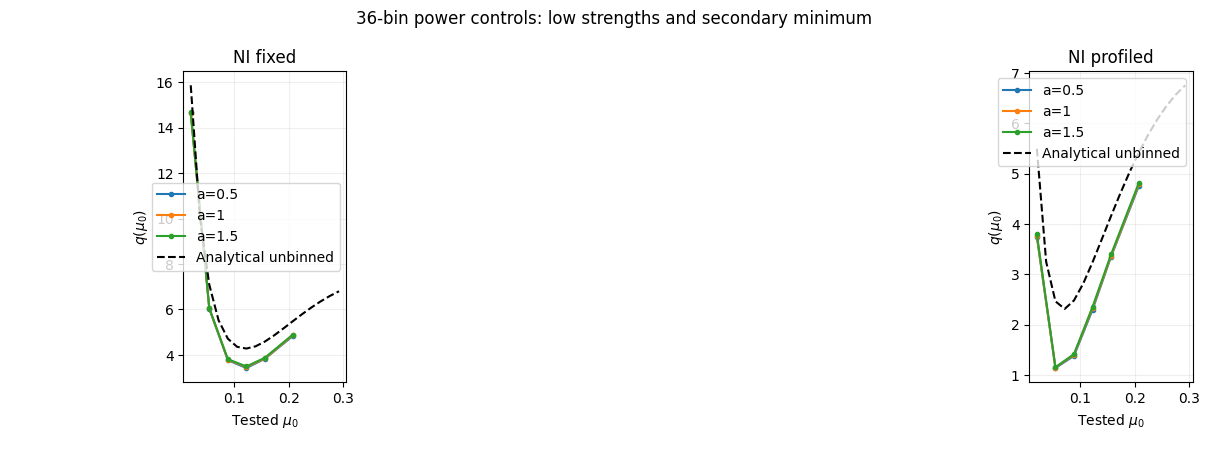

Power is kept fixed at 1.0 ; these paired controls do not automatically tune it.


In [17]:
from poodemo.power_study import run_power_study
POWER_VALUES = [0.5, 1.0, 1.5]
# Map positive probes to the actual scan so the analytical benchmark is matched.
POWER_ETA_TARGETS = [0.02, 0.05, 0.08, 0.12, 0.16, 0.20, 0.4, 0.8, 1.2]
POWER_ETAS = np.unique(np.r_[0., [scan_grid[np.argmin(abs(scan_grid-e))] for e in POWER_ETA_TARGETS]])
power_controls = run_power_study(run, samples, powers=POWER_VALUES, etas=POWER_ETAS, n_bins=N_BINS)
display(power_controls.loc[~power_controls.systematics,
    ['eta','power','reference_end_bin_fraction','reference_numerical_saturation_fraction','q','q_analytic','valid']])
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax,syst in zip(axes,[False,True]):
    for power,g in power_controls.loc[power_controls.systematics.eq(syst)&power_controls.eta.gt(0)&power_controls.eta.le(.3)].groupby('power'):
        ax.plot(g.eta,g.q.where(g.valid),'.-',label=f'a={power:g}')
        bad=g.loc[~g.valid]
        ax.plot(bad.eta,np.zeros(len(bad)),'rx',transform=ax.get_xaxis_transform(),clip_on=False)
    ref=unbinned.loc[unbinned.systematics.eq(syst)&unbinned.mu.le(.3)]
    ax.plot(ref.mu,ref.q.where(ref.valid),'k--',label='Analytical unbinned')
    ax.set(xlabel=r'Tested $\mu_0$',ylabel=r'$q(\mu_0)$',title='NI profiled' if syst else 'NI fixed')
    ax.legend()
fig.suptitle('36-bin power controls: low strengths and secondary minimum')
fig.tight_layout()
for ext in ('png','pdf'): fig.savefig(run.path('plots',f'04_power_controls.{ext}'),dpi=160,bbox_inches='tight')
plt.show()
print('Power is kept fixed at',REFERENCE_RATIO_A,'; these paired controls do not automatically tune it.')

In [18]:
from poodemo.signal_reference import publish_signal_baseline
baseline_manifest = publish_signal_baseline(mc_run, run, samples, templates, N_BINS)
print("Completed 04 baseline for notebook 05:",baseline_manifest)

Completed 04 baseline for notebook 05: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_04_baseline.json
